Upload the original image:


Saving 133883886687166516.jpg to 133883886687166516.jpg


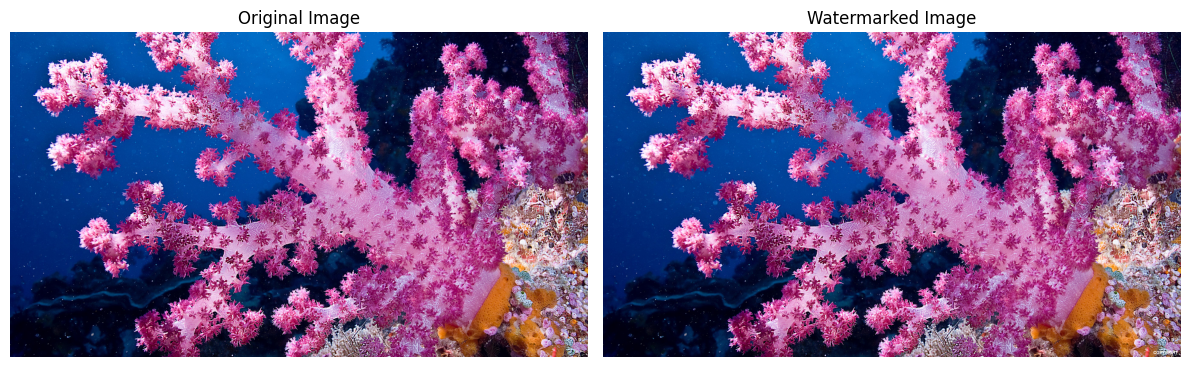

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Upload the original image
print("Upload the original image:")
uploaded = files.upload()
image_file = next(iter(uploaded))

# Read the original image
img = cv2.imread(image_file)

if img is None:
    print("Error: Original image not found!")
else:
    # Copy the original image
    watermarked = img.copy()

    # Add watermark text
    watermark = "COPYRIGHT"

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1
    thickness = 2

    # Get image dimensions
    height, width = img.shape[:2]

    # Set watermark position at bottom-right
    text_size = cv2.getTextSize(
        watermark, font, font_scale, thickness
    )[0]

    x = width - text_size[0] - 20
    y = height - 20

    # Insert watermark
    cv2.putText(
        watermarked,
        watermark,
        (max(10, x), max(text_size[1] + 10, y)),
        font,
        font_scale,
        (255, 255, 255),
        thickness,
        cv2.LINE_AA
    )

    # Convert images from BGR to RGB
    original_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    watermarked_rgb = cv2.cvtColor(
        watermarked, cv2.COLOR_BGR2RGB
    )

    # Display original and watermarked images
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(watermarked_rgb)
    plt.title("Watermarked Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Save the watermarked image
    cv2.imwrite("watermarked_image.jpg", watermarked)

    # Download the output
    files.download("watermarked_image.jpg")